# Mall Customer Segmentation using K-Means

**Objective:** Group mall customers into meaningful segments based on their age, income and spending behaviour, and derive marketing actions for each segment.

**Workflow**
1. Data loading and cleaning
2. Feature scaling
3. Choosing the number of clusters (Elbow method and Silhouette score)
4. K-Means clustering and visualization
5. Cluster profiling and marketing actions
6. Saving results and model evaluation

## 1. Import Libraries
Importing the libraries for data handling (pandas, numpy), preprocessing and clustering (scikit-learn) and plotting (matplotlib).

In [41]:
import pandas as pd

import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import matplotlib.pyplot as plt

## 2. Load the Dataset
The Mall Customers dataset contains `CustomerID`, `Genre`, `Age`, `Annual Income (k$)` and `Spending Score (1-100)`.

In [ ]:
data_frame = pd.read_csv("Data/Mall_Customers.csv")

## 3. Data Understanding and Cleaning
First, we inspect the structure of the data: column names, data types and the number of rows. This confirms that the dataset loaded correctly.

In [17]:
print(data_frame.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


Checking for missing values in every column. Missing values would need to be filled or removed before clustering.

In [18]:
print(data_frame.isnull().sum())

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


Checking for duplicate rows, since duplicates would give some customers extra weight in the clustering.

In [19]:
print(data_frame.duplicated().sum())

0


Looking at the first 20 rows to get a feel for the actual values in the dataset.

In [20]:
print(data_frame.head(20))

    CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0            1    Male   19                  15                      39
1            2    Male   21                  15                      81
2            3  Female   20                  16                       6
3            4  Female   23                  16                      77
4            5  Female   31                  17                      40
5            6  Female   22                  17                      76
6            7  Female   35                  18                       6
7            8  Female   23                  18                      94
8            9    Male   64                  19                       3
9           10  Female   30                  19                      72
10          11    Male   67                  19                      14
11          12  Female   35                  19                      99
12          13  Female   58                  20                 

Listing the exact column names so they can be renamed correctly in the next step.

In [21]:
print(data_frame.columns.tolist())

['CustomerID', 'Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


Renaming columns to shorter and cleaner names:
- `Annual Income (k$)` becomes `Income`
- `Spending Score (1-100)` becomes `SpendingScore`
- `Genre` becomes `Gender`

In [22]:
data_frame = data_frame.rename(
    columns={
        "Annual Income (k$)": "Income",
        "Spending Score (1-100)": "SpendingScore",
        "Genre" : "Gender",
    }
)

print(data_frame.columns.tolist())

['CustomerID', 'Gender', 'Age', 'Income', 'SpendingScore']


Removing any duplicate rows and rows with missing values, then resetting the index. This dataset is already clean, so this step is a safety measure.

In [23]:
data_frame = data_frame.drop_duplicates().dropna().reset_index(drop=True)

Encoding `Gender` as numbers (Male = 0, Female = 1). Gender is not used for clustering, but the encoded column lets us calculate the female ratio of each cluster during profiling.

In [24]:
data_frame["Gender"] = data_frame["Gender"].map(
    {
        "Male" : 0,
        "Female" : 1
    }
)

print(data_frame.head(10))

   CustomerID  Gender  Age  Income  SpendingScore
0           1       0   19      15             39
1           2       0   21      15             81
2           3       1   20      16              6
3           4       1   23      16             77
4           5       1   31      17             40
5           6       1   22      17             76
6           7       1   35      18              6
7           8       1   23      18             94
8           9       0   64      19              3
9          10       1   30      19             72


## 4. Feature Scaling
Features used for clustering: **Age, Income and SpendingScore**. `CustomerID` and `Gender` are excluded.

K-Means is distance-based, so features with larger ranges would dominate the result. `StandardScaler` converts each feature to mean 0 and standard deviation 1 so all features contribute equally.

In [25]:
features = ["Age", "Income", "SpendingScore"]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(data_frame[features])

## 5. Choosing the Number of Clusters (k)
K-Means is run for k = 2 to 10. Two measures are plotted:
- **Elbow method (inertia):** look for the point where the decrease in inertia slows down.
- **Silhouette score:** higher means better separated clusters.

The elbow bends between k = 4 and 6 and the silhouette score peaks at k = 6, so **k = 6** is selected.

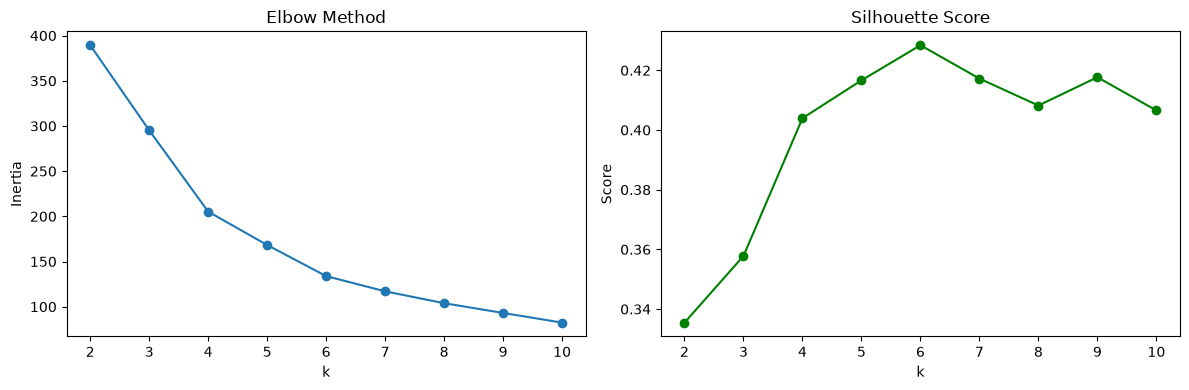

In [28]:
K_range = range(2, 11)

inertia, sil_score = [], []

for K in K_range:
    KM = KMeans(n_clusters=K, n_init=10, random_state=42)
    labels = KM.fit_predict(X_scaled)
    inertia.append(KM.inertia_)
    sil_score.append(silhouette_score(X_scaled, labels))


figure, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(K_range, inertia, "o-")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("k")
ax[0].set_ylabel("Inertia")
ax[1].plot(K_range, sil_score, "o-", color="green")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("k")
ax[1].set_ylabel("Score")
plt.tight_layout()
plt.savefig("elbow_silhouette.png", dpi=150)
plt.show()

## 6. Final K-Means Model
Fitting K-Means with k = 6 and storing each customer's cluster label in a new `Cluster` column.

In [29]:
K = 6

kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
data_frame["Cluster"] = kmeans.fit_predict(X_scaled)
print("\nSilhouette (final):", round(silhouette_score(X_scaled, data_frame["Cluster"]), 3))


Silhouette (final): 0.428


## 7. Cluster Visualization
Defining a color palette so every cluster has a consistent color across all plots.

In [30]:
colors = plt.cm.tab10.colors

**3D view (Age, Income, Spending Score):** shows all three clustering features together in the original scale.

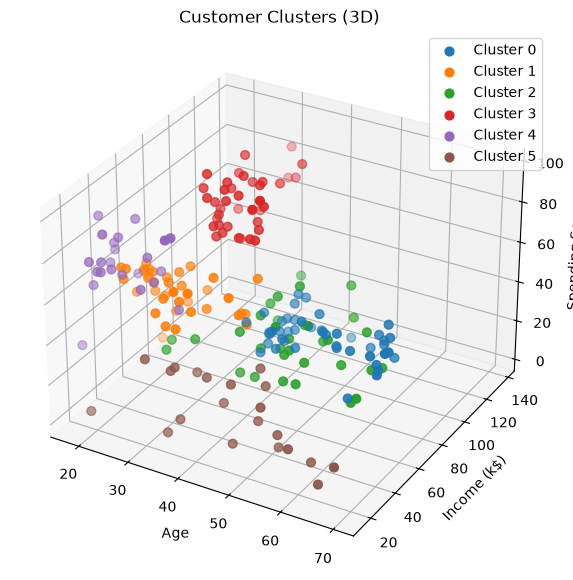

In [32]:
fig = plt.figure(figsize=(9, 7))
ax3d = fig.add_subplot(111, projection="3d")
for c in range(K):
    sub = data_frame[data_frame["Cluster"] == c]
    ax3d.scatter(sub["Age"], sub["Income"], sub["SpendingScore"],
                 color=colors[c], label=f"Cluster {c}", s=40)
ax3d.set_xlabel("Age")
ax3d.set_ylabel("Income (k$)")
ax3d.set_zlabel("Spending Score")
ax3d.set_title("Customer Clusters (3D)")
ax3d.legend()
plt.savefig("clusters_3d.png", dpi=150)
plt.show()

**PCA 2D view:** PCA reduces the three scaled features to two components so the clusters can be seen on a flat plot. The black X marks are the cluster centroids.

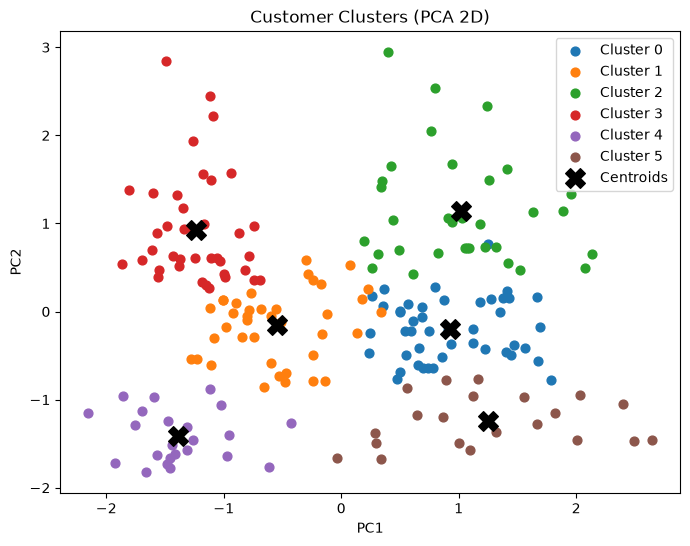

In [34]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
centers = pca.transform(kmeans.cluster_centers_)
 
plt.figure(figsize=(8, 6))
for c in range(K):
    mask = data_frame["Cluster"] == c
    plt.scatter(coords[mask, 0], coords[mask, 1], color=colors[c], label=f"Cluster {c}", s=40)
plt.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=200, label="Centroids")
plt.title("Customer Clusters (PCA 2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.savefig("clusters_pca.png", dpi=150)
plt.show()

**Income vs Spending Score:** the classic view for this dataset. It shows clearly how the segments differ in income and spending behaviour.

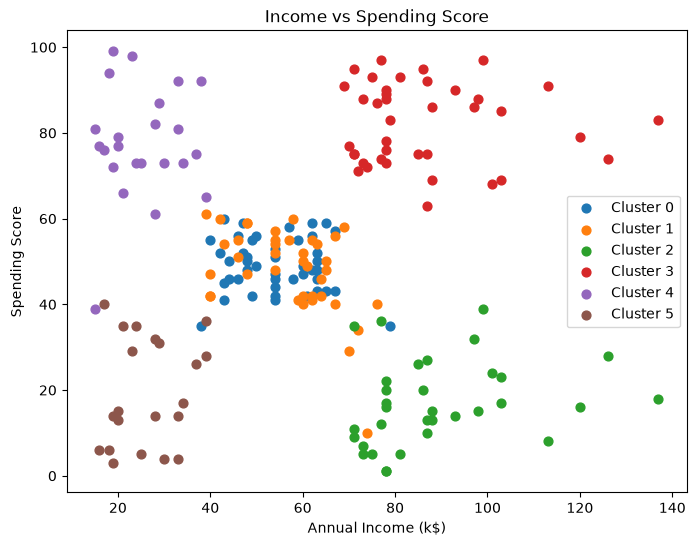

In [35]:
plt.figure(figsize=(8, 6))
for c in range(K):
    sub = data_frame[data_frame["Cluster"] == c]
    plt.scatter(sub["Income"], sub["SpendingScore"], color=colors[c], label=f"Cluster {c}", s=40)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Income vs Spending Score")
plt.legend()
plt.savefig("clusters_income_spending.png", dpi=150)
plt.show()

## 8. Cluster Profiling
For each cluster we calculate the number of customers, average age, average income, average spending score and female ratio. The overall averages are also stored for comparison in the next step.

In [38]:
profile = data_frame.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Age=("Age", "mean"),
    Avg_Income=("Income", "mean"),
    Avg_Spending=("SpendingScore", "mean"),
    Female_Ratio=("Gender", "mean"),
).round(1)
print("\nCluster Profile:\n", profile)
 
overall = data_frame[features].mean()


Cluster Profile:
          Customers  Avg_Age  Avg_Income  Avg_Spending  Female_Ratio
Cluster                                                            
0               45     56.3        54.3          49.1           0.6
1               39     26.8        57.1          48.1           0.6
2               33     41.9        88.9          17.0           0.4
3               39     32.7        86.5          82.1           0.5
4               23     25.0        25.3          77.6           0.6
5               21     45.5        26.3          19.4           0.6


## 9. Segment Names and Marketing Actions
Each cluster average is compared with the overall average to classify it by age group (Young / Middle-aged / Older), income level and spending level. Based on this combination, the function assigns a segment name and a suitable marketing action, then adds them to the profile table.

In [39]:

def describe_and_act(row):
    """Cluster ki averages ko overall average se compare karke label + marketing action."""
    age = "Young" if row["Avg_Age"] < overall["Age"] - 5 else (
        "Older" if row["Avg_Age"] > overall["Age"] + 5 else "Middle-aged")
    inc = "High-income" if row["Avg_Income"] > overall["Income"] + 10 else (
        "Low-income" if row["Avg_Income"] < overall["Income"] - 10 else "Mid-income")
    spd = "high-spending" if row["Avg_Spending"] > overall["SpendingScore"] + 10 else (
        "low-spending" if row["Avg_Spending"] < overall["SpendingScore"] - 10 else "moderate-spending")
 
    name = f"{age}, {inc}, {spd}"
 
    if inc == "High-income" and spd == "high-spending":
        action = "VIP/loyalty programme, premium launches, early access to new collections."
    elif inc == "High-income" and spd == "low-spending":
        action = "Untapped potential: personalised premium offers, luxury brands, exclusive events to raise engagement."
    elif inc == "Low-income" and spd == "high-spending":
        action = "Discounts, installment/cashback offers, bundle deals; watch for churn if prices rise."
    elif inc == "Low-income" and spd == "low-spending":
        action = "Low priority: low-cost coupons and seasonal sales only; avoid heavy marketing spend."
    elif spd == "high-spending":
        action = "Trend-driven offers, social media campaigns, loyalty points to keep them engaged."
    elif spd == "low-spending":
        action = "Re-engagement campaigns, targeted vouchers, survey to understand needs."
    else:
        action = "Cross-sell and upsell, reward-based programmes to nudge spending upward."
 
    if age == "Young":
        action += " Channel: Instagram/TikTok, events, trendy brands."
    elif age == "Older":
        action += " Channel: email/SMS, comfort and value-focused messaging."
    return pd.Series({"Segment_Name": name, "Marketing_Action": action})
 
 
profile = profile.join(profile.apply(describe_and_act, axis=1))

## 10. Saving the Results
Saving the following files:
- `mall_customers_with_clusters.csv`: the full dataset with cluster labels and segment names
- `cluster_profile_summary.csv`: the profile table of all clusters
- `segment_reports.md`: a short report for each segment

In [40]:
data_frame = data_frame.merge(profile[["Segment_Name"]], left_on="Cluster", right_index=True)
data_frame.sort_values("CustomerID").to_csv("mall_customers_with_clusters.csv", index=False)
profile.to_csv("cluster_profile_summary.csv")
 
with open("segment_reports.md", "w", encoding="utf-8") as f:
    f.write("# Mall Customer Segmentation Report\n\n")
    f.write(f"Method: K-Means (k={K}) on scaled Age, Income, Spending Score.\n\n")
    for c, r in profile.iterrows():
        f.write(f"## Segment {c}: {r['Segment_Name']}\n")
        f.write(f"- Size: {int(r['Customers'])} customers\n")
        f.write(f"- Avg age: {r['Avg_Age']} years\n")
        f.write(f"- Avg income: {r['Avg_Income']}k$\n")
        f.write(f"- Avg spending score: {r['Avg_Spending']}\n")
        f.write(f"- Female ratio: {r['Female_Ratio'] * 100:.0f}%\n")
        f.write(f"- **Recommended action:** {r['Marketing_Action']}\n\n")
 
print("\nSaved: mall_customers_with_clusters.csv, cluster_profile_summary.csv, segment_reports.md")


Saved: mall_customers_with_clusters.csv, cluster_profile_summary.csv, segment_reports.md


## 11. Model Evaluation
K-Means is unsupervised, so accuracy does not apply. Cluster quality is measured with:
- **Silhouette Score** (higher is better): 0.428 shows reasonably well-separated clusters.
- **Davies-Bouldin Index** (lower is better): 0.825 is below 1, which indicates compact clusters with little overlap.
- **Calinski-Harabasz Index** (higher is better): 135.1, useful mainly for comparing different models or k values.

**Conclusion:** the six segments are well defined and give a sound basis for targeted marketing.

In [42]:

labels = data_frame["Cluster"]
print("Silhouette       :", round(silhouette_score(X_scaled, labels), 3))
print("Davies-Bouldin   :", round(davies_bouldin_score(X_scaled, labels), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(X_scaled, labels), 1))

Silhouette       : 0.428
Davies-Bouldin   : 0.825
Calinski-Harabasz: 135.1
